# Expand the Hello World example to n-qubit GHZ state

In [11]:
%pip install qiskit qiskit_aer pylatexenc
%pip install matplotlib
%pip install qiskit_ibm_runtime


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Step 1: Map the problem to circuit & operators

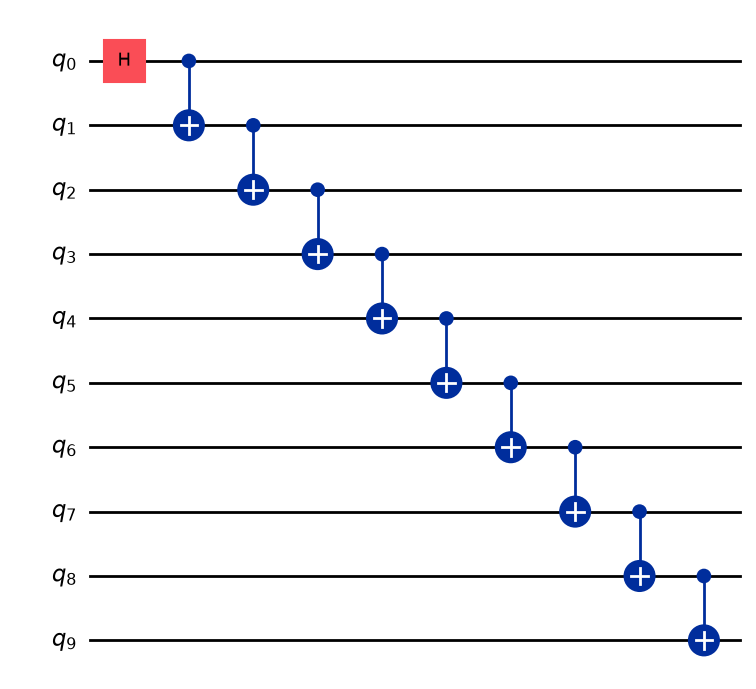

In [12]:
from qiskit import QuantumCircuit
qc = QuantumCircuit(2)

def get_qc_for_n_qubit_GHZ_state(n):
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(n-1):
        qc.cx(i, i+1)
    return qc

n = 10
qc = get_qc_for_n_qubit_GHZ_state(n)
qc.draw(output='mpl')

In [13]:
from qiskit.quantum_info import SparsePauliOp

operator_strings = ['Z' + 'I' * i + 'Z' + 'I' * (n-2-i) for i in range(n-1)]
print(operator_strings)
print(len(operator_strings))

operators = [SparsePauliOp(operator_strings) for operator_strings in operator_strings]
print(operators)

['ZZIIIIIIII', 'ZIZIIIIIII', 'ZIIZIIIIII', 'ZIIIZIIIII', 'ZIIIIZIIII', 'ZIIIIIZIII', 'ZIIIIIIZII', 'ZIIIIIIIZI', 'ZIIIIIIIIZ']
9
[SparsePauliOp(['ZZIIIIIIII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIZIIIIIII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIZIIIIII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIIZIIIII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIIIZIIII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIIIIZIII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIIIIIZII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIIIIIIZI'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIIIIIIIZ'],
              coeffs=[1.+0.j])]


## Step 2: Optimize the problem for Quantum Execution

In [14]:
# # uncomment this section if running on Google Colab
# # ensure a secret is already created as QUANTUM_API_KEY

# from google.colab import userdata
# quantum_api_key = userdata.get('QUANTUM_API_KEY')

# if quantum_api_key.strip():
#     print("API Key successfully captured!")

In [15]:
# uncomment this section if you are running in local computer and provide the key
from getpass import getpass
quantum_api_key = getpass("Type your quantum_api_key here: ")

if quantum_api_key.strip():
    print("API Key successfully captured!")

API Key successfully captured!


In [16]:
if not quantum_api_key.strip():
    print("API Key is empty. Please try again.")

from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService(channel="ibm_quantum_platform", token=quantum_api_key)

backend_name = 'ibm_kingston'     # 156 qubits
# backend_name = 'ibm_fez'          # 156 qubits
# backend_name = 'ibm_marrakesh'    # 156 qubits

backend = service.backend(name=backend_name)
backend.num_qubits

qiskit_runtime_service._discover_account:WARNING:2026-11-23 21:00:23,353: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-23 21:00:30,183: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: surnandi. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-23 21:00:30,184: Using instance: surnandi, plan: open


156

In [17]:
# from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend)

qc_transpiled = pass_manager.run(qc)
operators_transpiled_list = [op.apply_layout(qc_transpiled.layout) for op in operators]

## Step 3: Execute on the backend

In [18]:
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import EstimatorOptions

options = EstimatorOptions()
options.resilience_level = 1
# options.optimization_level = 1
options.dynamical_decoupling.enable = True
options.dynamical_decoupling.sequence_type = 'XY4'

estimator = Estimator(backend, options=options)
job = estimator.run([(qc_transpiled, operators_transpiled_list)])
job_id = job.job_id()
print(f"Job ID: {job_id}")

qiskit_runtime_service.backends:WARNING:2026-11-23 21:00:33,201: Using instance: surnandi, plan: open


Job ID: dc25o6qnj2vs73dg6hhg


## Step 4: Post process and plotting the results

In [19]:
job = service.job(job_id)

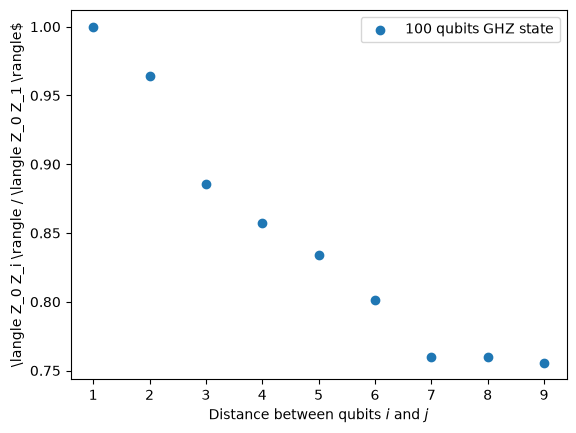

In [20]:
import matplotlib.pyplot as plt

data = list(range(1, len(operators) + 1))
result = job.result()[0]
values = result.data.evs
values = [v / values[0] for v in values]

plt.scatter(data, values, marker='o', label='100 qubits GHZ state')
plt.xlabel('Distance between qubits $i$ and $j$')
plt.ylabel(r'\langle Z_0 Z_i \rangle / \langle Z_0 Z_1 \rangle$')
plt.legend()
plt.show()
